# 01 — Understand the monthly nursing workforce series

**Goal:** Explore historical monthly equivalent nursing workforce (*PPE*) in a hospital. This repository uses **synthetic data** only: the numbers do not describe a real hospital.

## What does monthly PPE measure?

For each nursing employment contract, take the fraction of calendar days covered in the month and multiply it by its contracted working-time proportion. Add the contributions from all contracts:

$$
\mathrm{Monthly\ PPE} = \sum_{c \in \mathrm{contracts}} \left(\frac{\mathrm{contracted\ days\ in\ month}_c}{\mathrm{calendar\ days\ in\ month}}\right)\times\mathrm{working\ time\ fraction}_c
$$

For example, in a 30-day month, a full-time contract covering all 30 days contributes **1.00 PPE**, while a 50%-time contract covering 15 days contributes **0.25 PPE**. Together they contribute **1.25 PPE**. This is *not* a count of distinct people.

The demo dataset already contains **monthly aggregated synthetic PPE values**; it does not include contract-level records or reconstruct PPE from real contracts.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
assert (ROOT / "data").exists(), "Run Jupyter from the project root or notebooks/ folder."
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf
from src.ppe_forecasting import prepare_monthly_data

raw_path = ROOT / "data/raw/nursing_workforce_synthetic.csv"
clean_path = ROOT / "data/processed/nursing_workforce_monthly.csv"
df = prepare_monthly_data(raw_path)
print(f"{len(df)} observations: {df.index.min().date()} — {df.index.max().date()}")
display(df.head(3), df.tail(3))

130 observations: 2016-01-31 — 2026-10-31


,PPE
DATANOM,
2016-01-31,1117.01
2016-02-29,1126.76
2016-03-31,1133.51


,PPE
DATANOM,
2026-08-31,1566.29
2026-09-30,1543.35
2026-10-31,1541.92


## 1. Check the timeline

Every month must appear exactly once. A missing monthly observation is **missing information**, not a PPE value of zero. The data-preparation function checks this automatically.

In [2]:
print("Missing PPE values:", int(df["PPE"].isna().sum()))
print("Duplicate months:", int(df.index.duplicated().sum()))
print(df["PPE"].describe().round(2))

Missing PPE values: 0
Duplicate months: 0
count     130.00
mean     1326.12
std       141.97
min      1079.68
25%      1201.90
50%      1321.22
75%      1448.86
max      1569.67
Name: PPE, dtype: float64


## 2. Look for trend and seasonality

The 12-month rolling mean makes the long-run movement easier to spot. Seasonal decomposition separates the series into trend, repeating annual pattern and remaining fluctuations. These are exploratory views, not proof that future forecasts will be accurate.

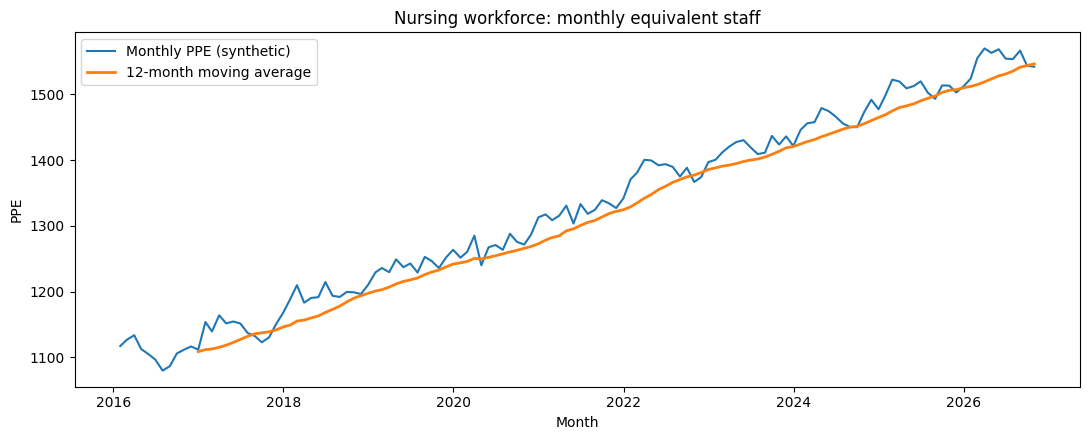

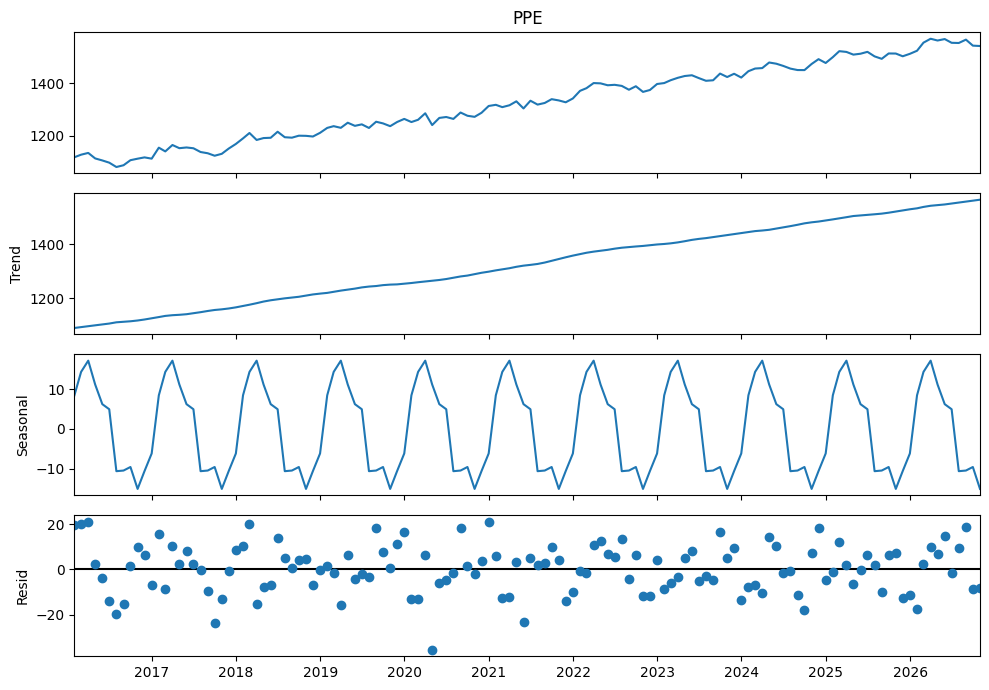

In [3]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(df.index, df["PPE"], label="Monthly PPE (synthetic)", linewidth=1.5)
ax.plot(df.index, df["PPE"].rolling(12).mean(), label="12-month moving average", linewidth=2)
ax.set(title="Nursing workforce: monthly equivalent staff", xlabel="Month", ylabel="PPE")
ax.legend()
fig.tight_layout()
fig.savefig(ROOT / "outputs/figures/01_series_and_trend.png", dpi=150)
plt.show()

decomp = seasonal_decompose(df["PPE"], model="additive", period=12, extrapolate_trend="freq")
fig = decomp.plot()
fig.set_size_inches(10, 7)
fig.tight_layout()
fig.savefig(ROOT / "outputs/figures/02_decomposition.png", dpi=150)
plt.show()

## 3. Does the past resemble the present?

Autocorrelation describes how observations relate to earlier months. We inspect it before forecasting, but rely on **out-of-sample testing** to decide whether a model is useful.

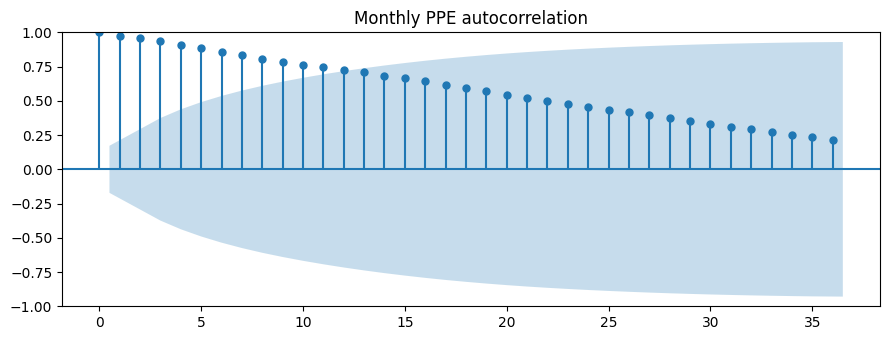

Clean monthly series: data/processed/nursing_workforce_monthly.csv


In [4]:
fig, ax = plt.subplots(figsize=(9, 3.5))
plot_acf(df["PPE"], lags=36, ax=ax)
ax.set_title("Monthly PPE autocorrelation")
fig.tight_layout()
plt.show()

clean_path.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(clean_path, index_label="DATANOM", float_format="%.2f")
print("Clean monthly series:", clean_path.relative_to(ROOT))